some trained models:

0. default: epochs=200, batch_size=8

1. model_1: epochs=10, batch_size=2

2. model_2: epochs=20, batch_size=2

3. model_3: epochs=20, batch_size=4

4. model_4: epochs=30, batch_size=2

5. ensemble: averaging model_1, 2, 3, und 4

6. feat_80_model: epoch=20, batch_size=2, max_feature_dim=80, max_model_dim=80, max_num_cluster=10

7. ensemble_3: combining the default model with models 1, 2, 3, and 4



https://neptune.ai/blog/f1-score-accuracy-roc-auc-pr-auc

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# paths of models
default_dir = "../results/adbench/context5000.feat100.R500.inf-fullFalse.LTFalse.gen1tr1True.reuse100.E200.step1000.bs8.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1/train_seed=0.transform=quantile.feat_truncation=subsampling"
model_1_dir = "../results/adbench/context5000.feat100.R500.inf-fullFalse.LTFalse.gen1tr1True.reuse100.E10.step1000.bs2.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1/train_seed=0.transform=quantile.feat_truncation=subsampling"
model_2_dir = "../results/adbench/context5000.feat100.R500.inf-fullFalse.LTFalse.gen1tr1True.reuse100.E20.step1000.bs2.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1/train_seed=0.transform=quantile.feat_truncation=subsampling"
model_3_dir = "../results/adbench/context5000.feat100.R500.inf-fullFalse.LTFalse.gen1tr1True.reuse100.E20.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1/train_seed=0.transform=quantile.feat_truncation=subsampling"
model_4_dir = "../results/adbench/context5000.feat100.R500.inf-fullFalse.LTFalse.gen1tr1True.reuse100.E30.step1000.bs2.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1/train_seed=0.transform=quantile.feat_truncation=subsampling"
ensemble_dir = "../results/adbench/ensemble/train_seed=0"
feat_80_model_dir = "../results/adbench/context5000.feat80.R500.inf-fullFalse.LTFalse.gen1tr1True.reuse100.E20.step1000.bs2.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1/train_seed=0.transform=quantile.feat_truncation=subsampling"
ensemble_3_dir = "../results/adbench/ensemble_3/train_seed=0"

### 1. Default model

In [3]:
default_aucroc_scores = []
default_aucpr_scores = []
default_f1_scores = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(default_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)

        # extract scores
        aucroc = df['aucroc'].values[0]
        default_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        default_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        default_f1_scores.append(f1)

# compute average scores of all datasets
default_avg_aucroc = sum(default_aucroc_scores) / len(default_aucroc_scores)
default_avg_aucpr = sum(default_aucpr_scores) / len(default_aucpr_scores)
default_avg_f1 = sum(default_f1_scores) / len(default_f1_scores)

print(f"number of datasets: {len(default_aucroc_scores)}")
print(f"Average aucroc: {default_avg_aucroc}")
print(f"Average aucpr: {default_avg_aucpr}")
print(f"Average f1: {default_avg_f1}")

number of datasets: 121
Average aucroc: 0.7590645511541744
Average aucpr: 0.4786638498057685
Average f1: 0.4666975187169514


### 2. Model_1

In [4]:
model_1_aucroc_scores = []
model_1_aucpr_scores = []
model_1_f1_scores = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_1_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)

        # extract scores
        aucroc = df['aucroc'].values[0]
        model_1_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_1_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_1_f1_scores.append(f1)

# compute average scores of all datasets
model_1_avg_aucroc = sum(model_1_aucroc_scores) / len(model_1_aucroc_scores)
model_1_avg_aucpr = sum(model_1_aucpr_scores) / len(model_1_aucpr_scores)
model_1_avg_f1 = sum(model_1_f1_scores) / len(model_1_f1_scores)

print(f"number of datasets: {len(model_1_aucroc_scores)}")
print(f"Average aucroc: {model_1_avg_aucroc}")
print(f"Average aucpr: {model_1_avg_aucpr}")
print(f"Average f1: {model_1_avg_f1}")

number of datasets: 121
Average aucroc: 0.7008943315112038
Average aucpr: 0.4009097034205178
Average f1: 0.3924483452887953


### 3. Model_2

In [5]:
model_2_aucroc_scores = []
model_2_aucpr_scores = []
model_2_f1_scores = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_2_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)

        # extract scores
        aucroc = df['aucroc'].values[0]
        model_2_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_2_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_2_f1_scores.append(f1)

# compute average scores of all datasets
model_2_avg_aucroc = sum(model_2_aucroc_scores) / len(model_2_aucroc_scores)
model_2_avg_aucpr = sum(model_2_aucpr_scores) / len(model_2_aucpr_scores)
model_2_avg_f1 = sum(model_2_f1_scores) / len(model_2_f1_scores)

print(f"number of datasets: {len(model_2_aucroc_scores)}")
print(f"Average aucroc: {model_2_avg_aucroc}")
print(f"Average aucpr: {model_2_avg_aucpr}")
print(f"Average f1: {model_2_avg_f1}")

number of datasets: 121
Average aucroc: 0.7186872500968602
Average aucpr: 0.42481230457200025
Average f1: 0.41632704128468684


### 4. Model_3

In [6]:
model_3_aucroc_scores = []
model_3_aucpr_scores = []
model_3_f1_scores = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_3_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)

        # extract scores
        aucroc = df['aucroc'].values[0]
        model_3_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_3_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_3_f1_scores.append(f1)

# compute average scores of all datasets
model_3_avg_aucroc = sum(model_3_aucroc_scores) / len(model_3_aucroc_scores)
model_3_avg_aucpr = sum(model_3_aucpr_scores) / len(model_3_aucpr_scores)
model_3_avg_f1 = sum(model_3_f1_scores) / len(model_3_f1_scores)

print(f"number of datasets: {len(model_3_aucroc_scores)}")
print(f"Average aucroc: {model_3_avg_aucroc}")
print(f"Average aucpr: {model_3_avg_aucpr}")
print(f"Average f1: {model_3_avg_f1}")

number of datasets: 121
Average aucroc: 0.7249775360785166
Average aucpr: 0.4341971090507112
Average f1: 0.41580002920536835


### 5. Model_4

In [7]:
model_4_aucroc_scores = []
model_4_aucpr_scores = []
model_4_f1_scores = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_4_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)

        # extract scores
        aucroc = df['aucroc'].values[0]
        model_4_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_4_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_4_f1_scores.append(f1)

# compute average scores of all datasets
model_4_avg_aucroc = sum(model_4_aucroc_scores) / len(model_4_aucroc_scores)
model_4_avg_aucpr = sum(model_4_aucpr_scores) / len(model_4_aucpr_scores)
model_4_avg_f1 = sum(model_4_f1_scores) / len(model_4_f1_scores)

print(f"number of datasets: {len(model_4_aucroc_scores)}")
print(f"Average aucroc: {model_4_avg_aucroc}")
print(f"Average aucpr: {model_4_avg_aucpr}")
print(f"Average f1: {model_4_avg_f1}")

number of datasets: 121
Average aucroc: 0.721563656216457
Average aucpr: 0.42834347411031626
Average f1: 0.41139869785448663


### 6. ensemble model

In [8]:
ensemble_aucroc_scores = []
ensemble_aucpr_scores = []
ensemble_f1_scores = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(ensemble_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)

        # extract scores
        aucroc = df['aucroc'].values[0]
        ensemble_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        ensemble_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        ensemble_f1_scores.append(f1)

# compute average scores of all datasets
ensemble_avg_aucroc = sum(ensemble_aucroc_scores) / len(ensemble_aucroc_scores)
ensemble_avg_aucpr = sum(ensemble_aucpr_scores) / len(ensemble_aucpr_scores)
ensemble_avg_f1 = sum(ensemble_f1_scores) / len(ensemble_f1_scores)

print(f"number of datasets: {len(ensemble_aucroc_scores)}")
print(f"Average aucroc: {ensemble_avg_aucroc}")
print(f"Average aucpr: {ensemble_avg_aucpr}")
print(f"Average f1: {ensemble_avg_f1}")

number of datasets: 121
Average aucroc: 0.7469414908196659
Average aucpr: 0.45738605741063
Average f1: 0.4455655048637238


### 7. ensemble_3

In [9]:
ensemble_3_aucroc_scores = []
ensemble_3_aucpr_scores = []
ensemble_3_f1_scores = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(ensemble_3_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)

        # extract scores
        aucroc = df['aucroc'].values[0]
        ensemble_3_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        ensemble_3_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        ensemble_3_f1_scores.append(f1)

# compute average scores of all datasets
ensemble_3_avg_aucroc = sum(ensemble_3_aucroc_scores) / len(ensemble_3_aucroc_scores)
ensemble_3_avg_aucpr = sum(ensemble_3_aucpr_scores) / len(ensemble_3_aucpr_scores)
ensemble_3_avg_f1 = sum(ensemble_3_f1_scores) / len(ensemble_3_f1_scores)

print(f"number of datasets: {len(ensemble_3_aucroc_scores)}")
print(f"Average aucroc: {ensemble_3_avg_aucroc}")
print(f"Average aucpr: {ensemble_3_avg_aucpr}")
print(f"Average f1: {ensemble_3_avg_f1}")

number of datasets: 121
Average aucroc: 0.7595119795233568
Average aucpr: 0.4688175024856235
Average f1: 0.45479593145265823


### 8. feat_80_model

In [10]:
feat_80_model_aucroc_scores = []
feat_80_model_aucpr_scores = []
feat_80_model_f1_scores = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(feat_80_model_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)

        # extract scores
        aucroc = df['aucroc'].values[0]
        feat_80_model_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        feat_80_model_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        feat_80_model_f1_scores.append(f1)

# compute average scores of all datasets
feat_80_model_avg_aucroc = sum(feat_80_model_aucroc_scores) / len(feat_80_model_aucroc_scores)
feat_80_model_avg_aucpr = sum(feat_80_model_aucpr_scores) / len(feat_80_model_aucpr_scores)
feat_80_model_avg_f1 = sum(feat_80_model_f1_scores) / len(feat_80_model_f1_scores)

print(f"number of datasets: {len(feat_80_model_aucroc_scores)}")
print(f"Average aucroc: {feat_80_model_avg_aucroc}")
print(f"Average aucpr: {feat_80_model_avg_aucpr}")
print(f"Average f1: {feat_80_model_avg_f1}")

number of datasets: 121
Average aucroc: 0.7219098312030479
Average aucpr: 0.42651203259347353
Average f1: 0.4145596581983032


### Visualization

In [11]:
models = ['Epochs_200_batch_8(Default)', 'Epochs_10_batch_2', 'Epochs_20_batch_2', 'Epochs_20_batch_4', 'Epochs_30_batch_2', 'Ensemble', 'Ensemble_3', 'Feat_80_model']
avg_aucroc_scores = [round(default_avg_aucroc, 2), round(model_1_avg_aucroc, 2), round(model_2_avg_aucroc, 2), round(model_3_avg_aucroc, 2), round(model_4_avg_aucroc, 2), round(ensemble_avg_aucroc, 2), round(ensemble_3_avg_aucroc, 2), round(feat_80_model_avg_aucroc, 2)]
avg_aucpr_scores = [round(default_avg_aucpr, 2), round(model_1_avg_aucpr, 2), round(model_2_avg_aucpr, 2), round(model_3_avg_aucpr, 2), round(model_4_avg_aucpr, 2), round(ensemble_avg_aucpr, 2), round(ensemble_3_avg_aucpr, 2), round(feat_80_model_avg_aucpr, 2)]
avg_f1_scores = [round(default_avg_f1, 2), round(model_1_avg_f1, 2), round(model_2_avg_f1, 2), round(model_3_avg_f1, 2), round(model_4_avg_f1, 2), round(ensemble_avg_f1, 2), round(ensemble_3_avg_f1, 2), round(feat_80_model_avg_f1, 2)]

summary_dict = {'models': models, 'average_aucroc': avg_aucroc_scores, 'average_aucpr': avg_aucpr_scores, 'average_f1': avg_f1_scores}

In [12]:
summary_results = pd.DataFrame(summary_dict)

In [13]:
summary_results

,models,average_aucroc,average_aucpr,average_f1
0,Epochs_200_batch_8(Default),0.76,0.48,0.47
1,Epochs_10_batch_2,0.70,0.40,0.39
2,Epochs_20_batch_2,0.72,0.42,0.42
3,Epochs_20_batch_4,0.72,0.43,0.42
4,Epochs_30_batch_2,0.72,0.43,0.41
5,Ensemble,0.75,0.46,0.45
6,Ensemble_3,0.76,0.47,0.45
7,Feat_80_model,0.72,0.43,0.41


In [14]:
models_2 = ['Epochs_200_batch_8(Default)', 'Epochs_10_batch_2', 'Epochs_20_batch_2', 'Epochs_20_batch_4', 'Epochs_30_batch_2', 'Ensemble', 'Ensemble_3', 'Feat_80_model']
avg_aucroc_scores_2 = [round(default_avg_aucroc, 4), round(model_1_avg_aucroc, 4), round(model_2_avg_aucroc, 4), round(model_3_avg_aucroc, 4), round(model_4_avg_aucroc, 4), round(ensemble_avg_aucroc, 4), round(ensemble_3_avg_aucroc, 4), round(feat_80_model_avg_aucroc, 4)]
avg_aucpr_scores_2 = [round(default_avg_aucpr, 4), round(model_1_avg_aucpr, 4), round(model_2_avg_aucpr, 4), round(model_3_avg_aucpr, 4), round(model_4_avg_aucpr, 4), round(ensemble_avg_aucpr, 4), round(ensemble_3_avg_aucpr, 4), round(feat_80_model_avg_aucpr, 4)]
avg_f1_scores_2 = [round(default_avg_f1, 4), round(model_1_avg_f1, 4), round(model_2_avg_f1, 4), round(model_3_avg_f1, 4), round(model_4_avg_f1, 4), round(ensemble_avg_f1, 4), round(ensemble_3_avg_f1, 4), round(feat_80_model_avg_f1, 4)]

summary_dict_2 = {'models': models_2, 'average_aucroc': avg_aucroc_scores_2, 'average_aucpr': avg_aucpr_scores_2, 'average_f1': avg_f1_scores_2}
summary_results_2 = pd.DataFrame(summary_dict_2)
summary_results_2

,models,average_aucroc,average_aucpr,average_f1
0,Epochs_200_batch_8(Default),0.7591,0.4787,0.4667
1,Epochs_10_batch_2,0.7009,0.4009,0.3924
2,Epochs_20_batch_2,0.7187,0.4248,0.4163
3,Epochs_20_batch_4,0.7250,0.4342,0.4158
4,Epochs_30_batch_2,0.7216,0.4283,0.4114
5,Ensemble,0.7469,0.4574,0.4456
6,Ensemble_3,0.7595,0.4688,0.4548
7,Feat_80_model,0.7219,0.4265,0.4146


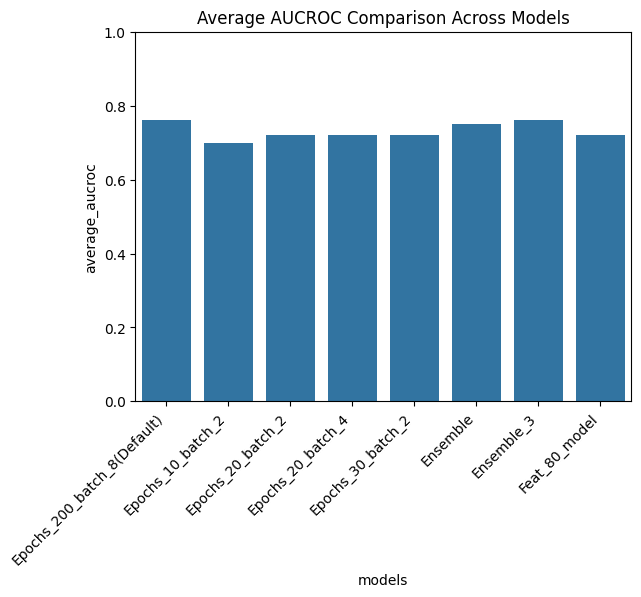

In [15]:
sns.barplot(data=summary_results, x="models", y="average_aucroc")
plt.ylim(0,1)
plt.title("Average AUCROC Comparison Across Models")
plt.xticks(rotation=45, ha="right")
plt.show()

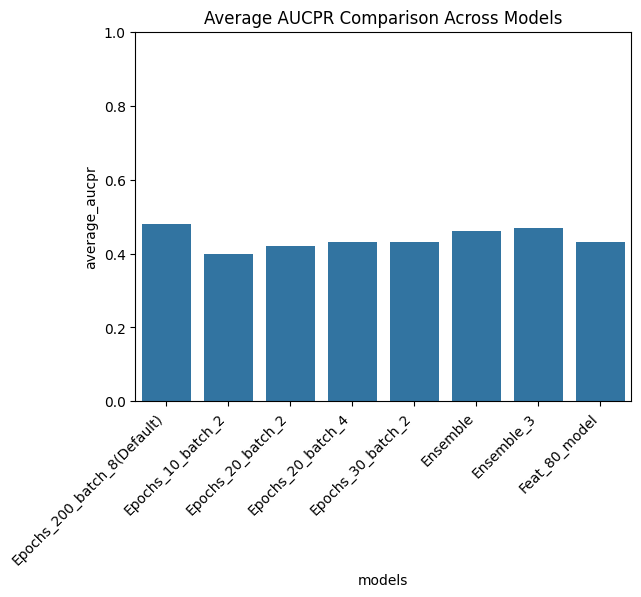

In [16]:
sns.barplot(data=summary_results, x="models", y="average_aucpr")
plt.ylim(0,1)
plt.title("Average AUCPR Comparison Across Models")
plt.xticks(rotation=45, ha="right")
plt.show()